---
title: "Model development"
subtitle: "CHEG 401 *Chemical Process Dynamics and Control*"

author:
  - name: "Kyle Wodehouse"
    email: "kwode@udel.edu"
    affiliations:
      - id: udel
        name: "University of Delaware"
        department: "Department of Chemical Engineering"
        city: "Newark"
        region: "DE"
        country: "United States"
        url: "https://www.udel.edu/"

date: today
date-format: "MMMM D, YYYY"
lang: en-US

format:
  html:
    self-contained: true
    toc: false
    number-sections: false
    smooth-scroll: true
---

In [1147]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lmfit

`patient:1` is MAP, `patient:2` is CO. here i bring in data i exported from simulink.

<Axes: title={'center': 'SNP'}, xlabel='time'>

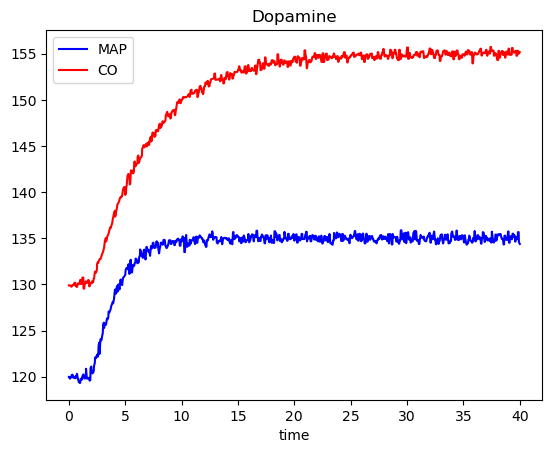

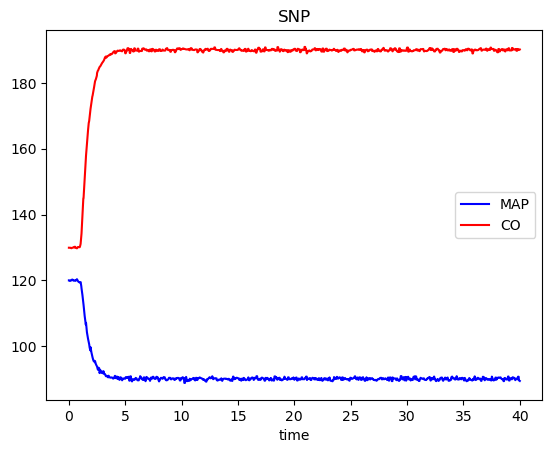

In [1148]:
dopamine = pd.read_excel('dopamine_0-5_time0.xlsx').rename(columns={'Patient:1': 'MAP', 'Patient:2': 'CO'})
SNP = pd.read_excel('SNP_0-5_time0.xlsx').rename(columns={'Patient:1': 'MAP', 'Patient:2': 'CO'})

dopamine.plot(x='time', title='Dopamine', color={'MAP': 'blue', 'CO': 'red'})
SNP.plot(x='time', title='SNP', color={'MAP': 'blue', 'CO': 'red'})

- from visual inspection, looks like old steady state for MAP was 120 and old steady state for CO is 130.


we're fitting the response to 13.4 from the textbook.

$$ y(t)=\left\{\begin{array}{ll}0;&t<\alpha\\ A K(1-e^{-(t-\alpha)/\tau});&t\geq\alpha.\end{array}\right. \tag{13.4}$$

In [1149]:
def response(t, alpha, K, tau, A):
    ''' time domain response of first order + time delay transfer function 
        (1) eq. 13.4 from the textbook '''
    t = np.asarray(t)
    return np.where(t < alpha, 0, A * K * (1 - np.exp(-(t - alpha) / tau)))

In [1150]:
#| echo: false
# t_test = np.linspace(0,30,100)
# alpha_test, K_test, tau_test, A_test = 4.0, 12.0, 3.0, 5.0
# y = np.vectorize(response, otypes=[float])(t_test, alpha_test, K_test, tau_test, A_test)
# fig,ax = plt.subplots(figsize=(5,3))
# plt.plot(t_test, y);

using python's `lmfit`, and remembering that the step input i used in simulink had $A=5$

In [1151]:
model = lmfit.Model(response)
model.set_param_hint('A', value=5.0, vary=False)

now we can fit the first order + time delay to each response.

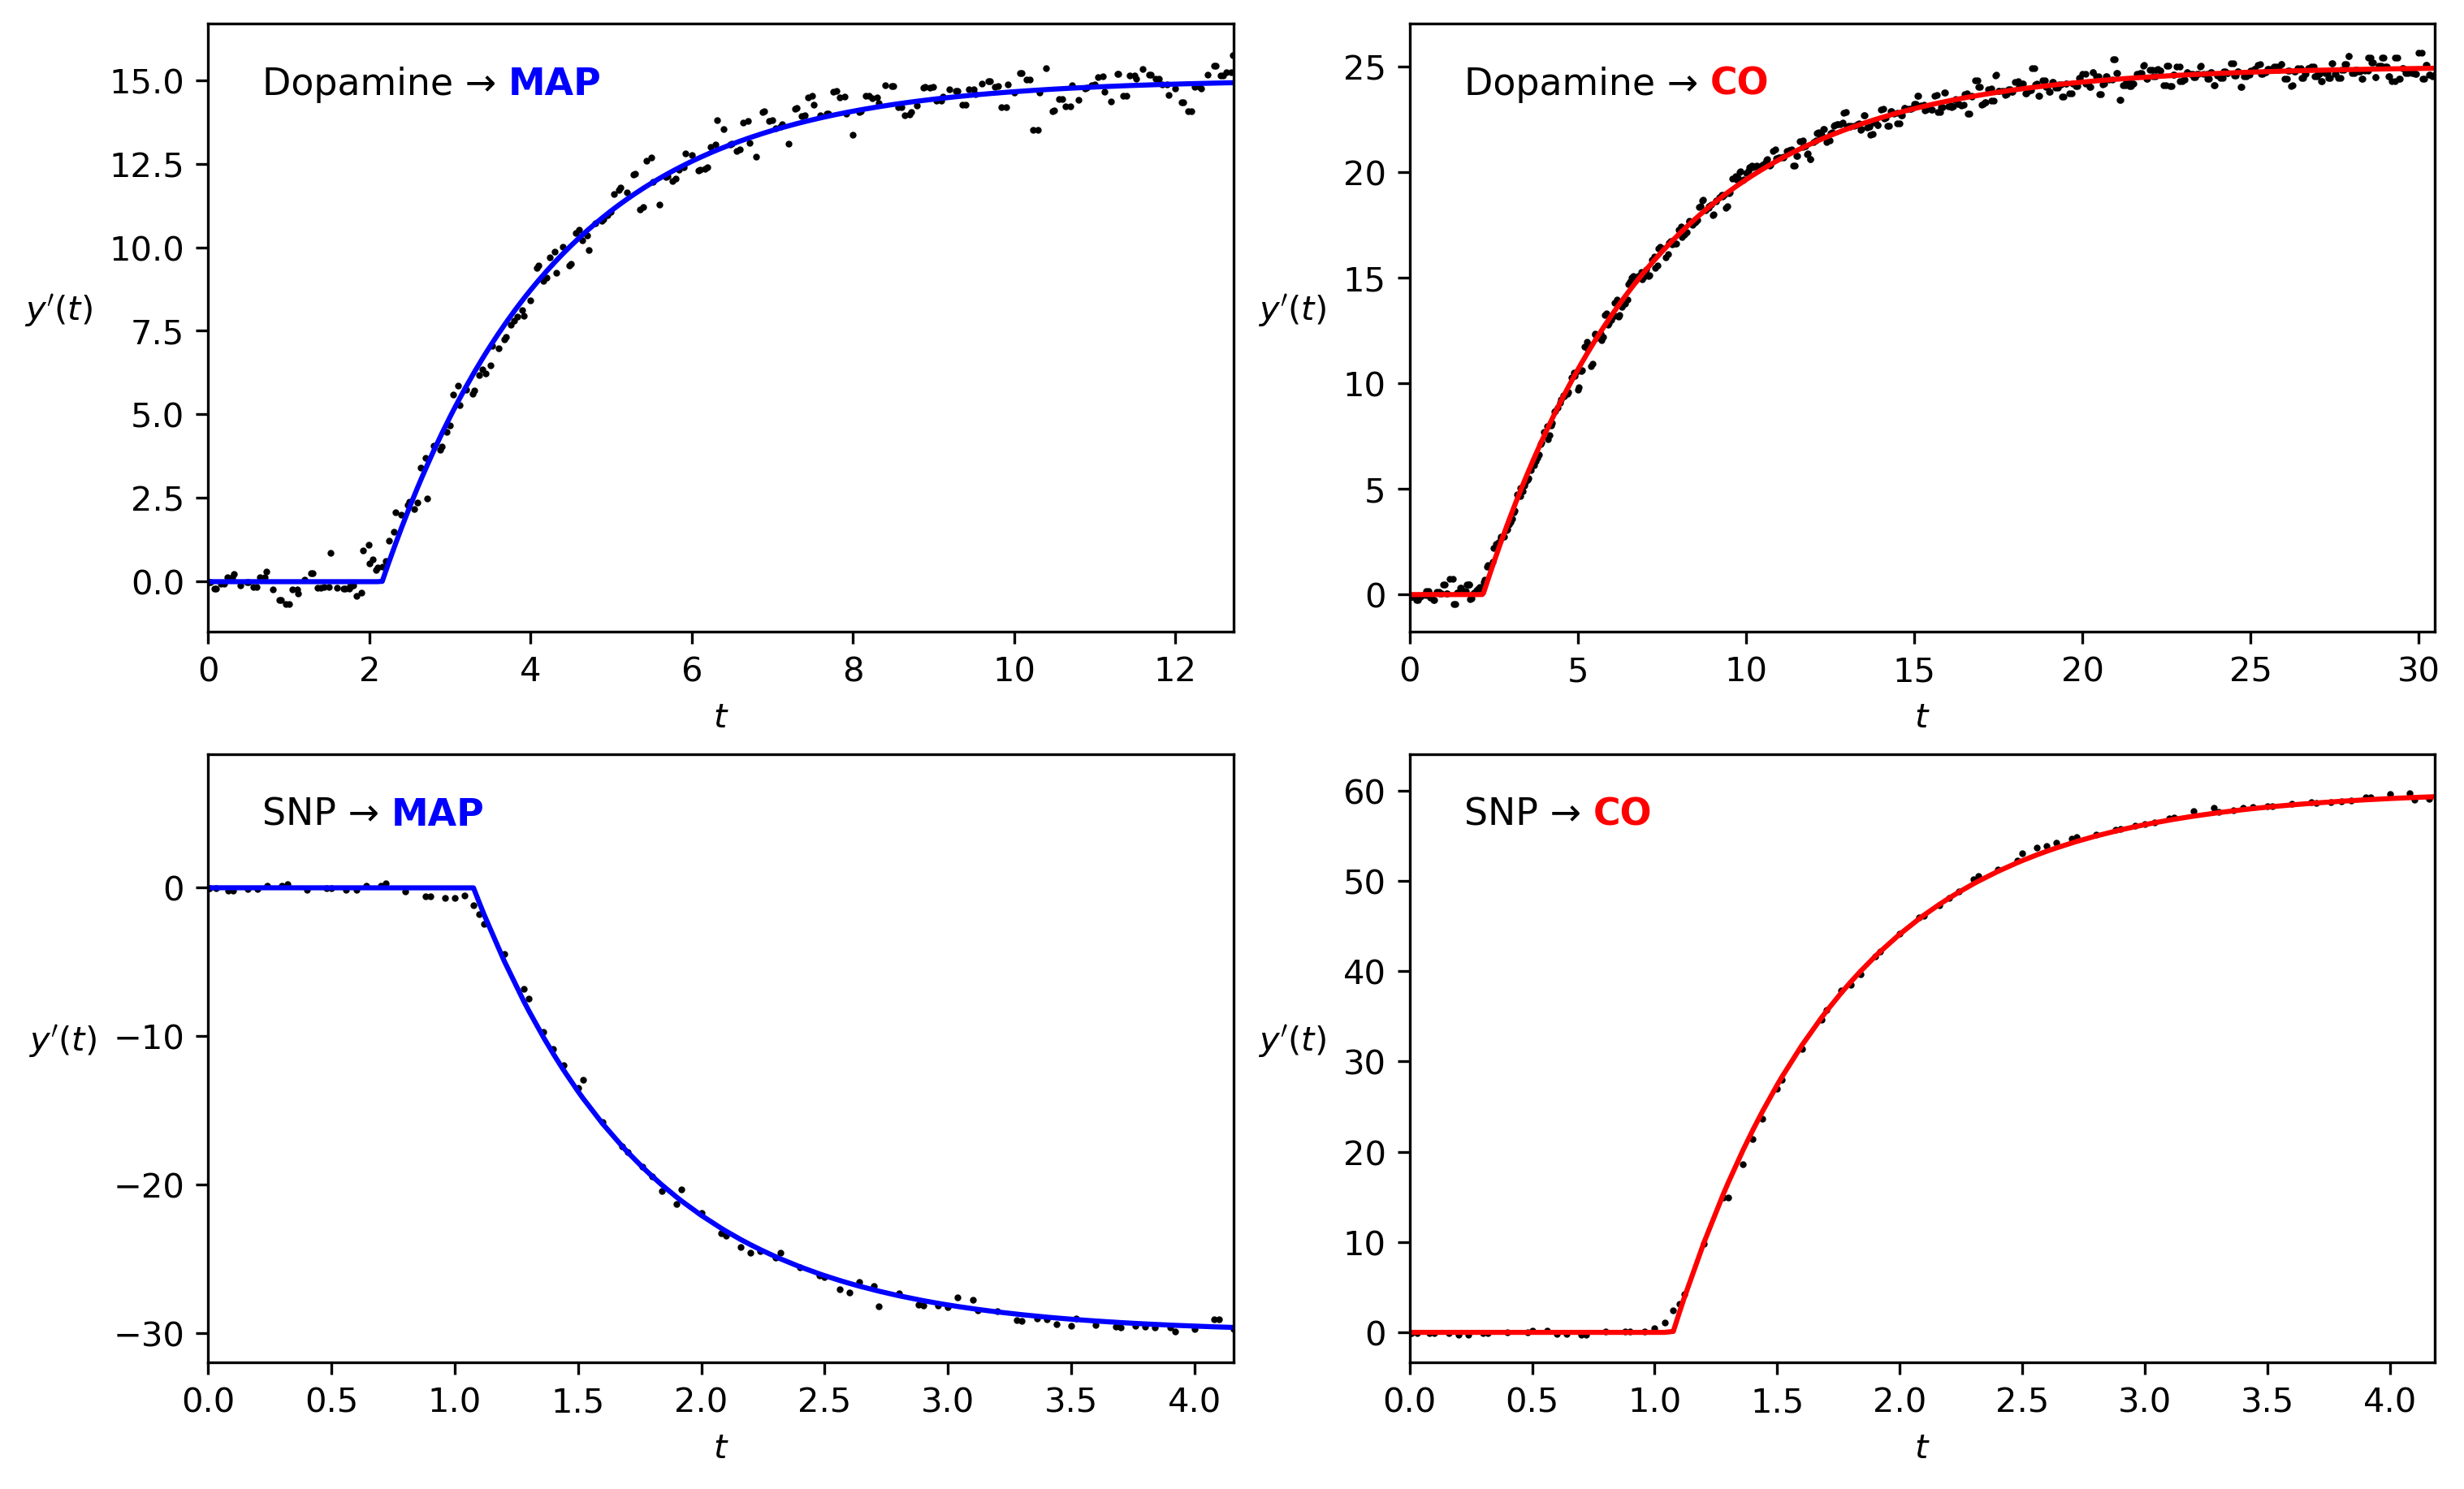

In [1152]:
fig,ax = plt.subplots(2,2, dpi=300, figsize=(10,6), layout='constrained')
axes = np.ravel(ax)

fits = []
i = 0
for drug, df in zip(['Dopamine', 'SNP'], [dopamine, SNP]):
    for col, previous_ss in zip(['MAP', 'CO'], [120,130]):
        x = df['time'].to_numpy()
        y = df[col].to_numpy()
        y -= previous_ss

        result = model.fit(y, t=x, alpha=1, K=y[-1]/5, tau=5, A=5)
        fits.append(dict(drug=drug, variable=col, previous_ss=previous_ss, result=result))

        color = 'blue' if col == 'MAP' else 'red'
        ax = axes[i]
        ax.scatter(x, y, s=1, c='black')
        ax.plot(x, result.best_fit, '-', c=color)
        ax.set(xlim=(0,result.best_values['tau']*6), xlabel='$t$')
        ax.set_ylabel(ylabel="$y'(t)$", rotation=0, labelpad=15)
        from matplotlib.offsetbox import AnchoredOffsetbox, HPacker, TextArea
        label = HPacker(children=[
            TextArea(f'{drug} \u2192 ', textprops=dict(fontsize=11)),
            TextArea(col, textprops=dict(color=color, fontsize=11, fontweight='bold')),
        ], align='baseline', pad=0, sep=0)
        ax.add_artist(AnchoredOffsetbox(loc='upper left', child=label, pad=0.2, frameon=False,
                                        bbox_to_anchor=(0.03, 0.97), bbox_transform=ax.transAxes))
        if (drug, col) == ('SNP', 'MAP'):
            ax.set_ylim(-32, 9)
        i += 1

fig.savefig('fits.pdf')

tabulating the fit values

In [1153]:
rows = []
for f in fits:
    p = f['result'].params
    r = f['result']
    rows.append({
        'drug': f['drug'],
        'variable': f['variable'],
        r'$\alpha$': p['alpha'].value, 
        'K': p['K'].value, 
        r'$\tau$': p['tau'].value, 
        'R$^2$': 1 - np.var(r.residual) / np.var(r.data),
    })
summary = pd.DataFrame(rows).set_index(['drug', 'variable'])
summary.map(lambda v: f'{v:.3g}').to_latex('summary')
summary.map(lambda v: f'{v:.3g}')

$\alpha$   K $\tau$  R$^2$
drug     variable                           
Dopamine MAP          2.16   3   2.12  0.992
         CO           2.18   5   5.08  0.998
SNP      MAP          1.08  -6  0.693  0.996
         CO           1.07  12  0.697  0.999

---

### changing both at once

here, i bring in another exported signal from simulink where i change them both from 5 to 10 at time=20. this is to see if the model fit to individual changes will 'generalize' into a model that describes changes to both infusion rates @ once.

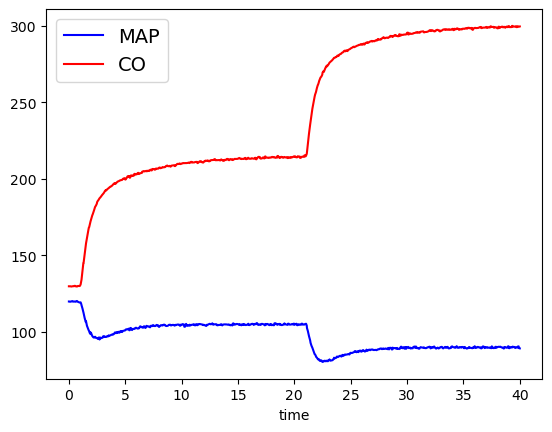

In [1154]:
testcase = pd.read_excel('test_0-5_both_t=20.xlsx')
ax = testcase.plot(x='time', color={'MAP': 'blue', 'CO': 'red'})
ax.legend(fontsize=14);

here i...

- turn y into deviation varible by taking the average of y right before the step at t=20
- predict response from the FOPTD model fit earlier in this notebook

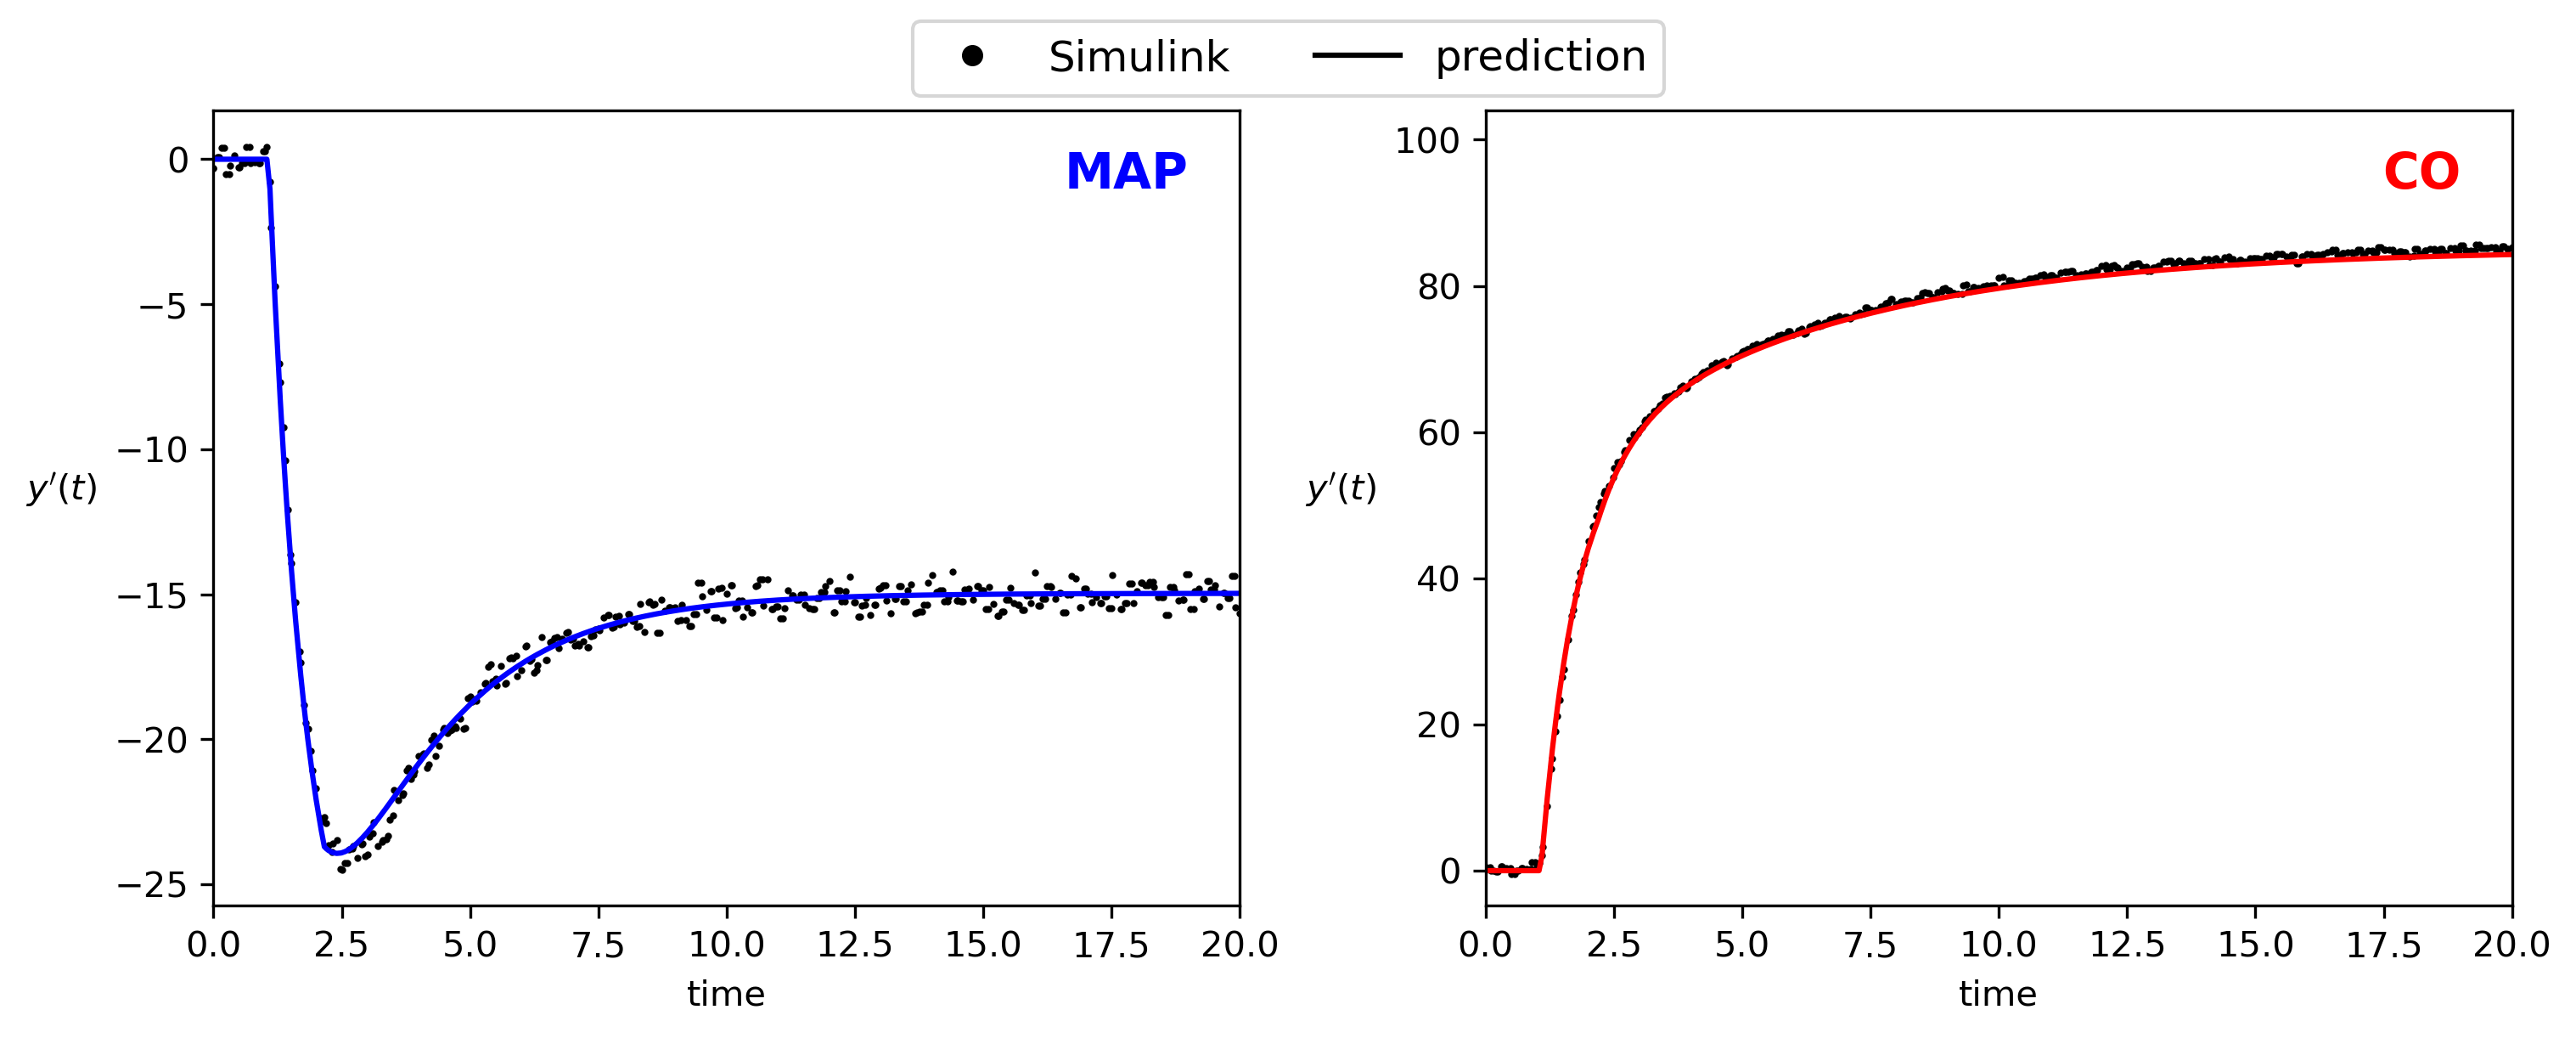

In [ ]:
t_step = 20
pre = testcase[(testcase['time'] >= 19) & (testcase['time'] <= 20.5)]
ss = pre[['MAP', 'CO']].mean()

# deviation variables: y'(t) = y(t) - steady state
post = testcase[testcase['time'] >= t_step].copy()
post['MAP_dev'] = post['MAP'] - ss['MAP']
post['CO_dev'] = post['CO'] - ss['CO']

params = {(f['drug'], f['variable']): f['result'].best_values for f in fits}

def predict(var, t):
    return sum(response(t - t_step, p['alpha'], p['K'], p['tau'], p['A'])
               for drug in ['Dopamine', 'SNP']
               for p in [params[(drug, var)]])

post['MAP_pred'] = predict('MAP', post['time'].to_numpy())
post['CO_pred'] = predict('CO', post['time'].to_numpy())

fig, ax = plt.subplots(1, 2, figsize=(10, 4), layout='constrained', dpi=300)
for a, var in zip(ax, ['MAP', 'CO']):
    color = 'blue' if var == 'MAP' else 'red'
    a.scatter(post['time']-20, post[f'{var}_dev'], s=1, c='black')
    a.plot(post['time']-20, post[f'{var}_pred'], '-', c=color)
    a.set_ylabel("$y'(t)$", rotation=0, labelpad=15)
    a.annotate(var, xy=(0.95, 0.95), xycoords='axes fraction', ha='right', va='top',
               color=color, fontsize=14, fontweight='bold')
    a.set(xlim=(0,20), xlabel='time')
    if var == 'CO':
        current_y_lim = a.get_ylim()
        a.set(ylim=(current_y_lim[0], 104))


from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', ls='', color='black', markersize=5, label='Simulink'),
           Line2D([], [], ls='-', color='black', label='prediction')]
fig.legend(handles=handles, loc='outside upper center', ncol=2, fontsize=12)
fig.savefig('double_step_response.pdf')

the agreement is great. it is not perfect, but that is okay since this is just a FOPTD approximation. 

---